     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 1.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 3.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 240.3/240.3 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 32.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 44.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 29.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.4/42.4 MB 12.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.1 which is incompatible.
bqplot 0.12.45 requires pandas<3.0.0,>=1.0.0, but you have pandas 3.0.1 which is incompatible.
gradio 5.50.0 requires pandas<3.0,>=1.0, but you have pandas 3.0.1 which is incompat

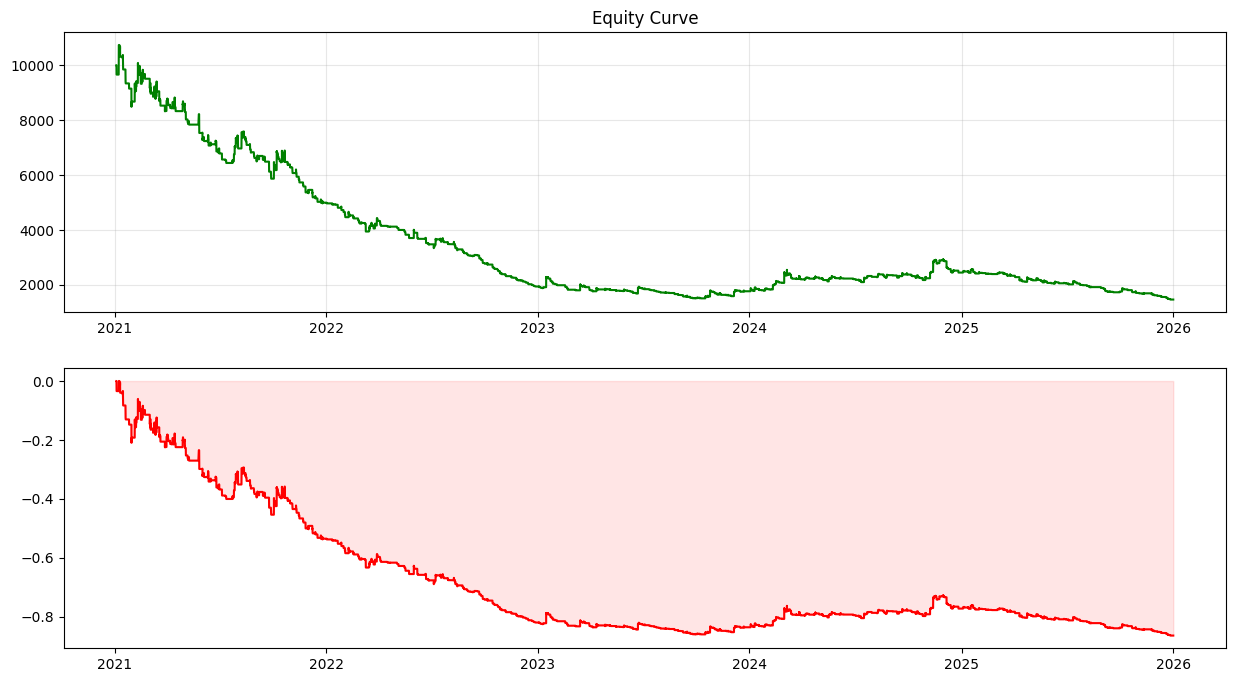

In [1]:
# ==============================================================================
# BƯỚC 1: CÀI ĐẶT THƯ VIỆN
# ==============================================================================
!pip install pandas_ta -q

import requests
import time
import pandas as pd
import pandas_ta as ta
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# ==============================================================================
# BƯỚC 2: CẤU HÌNH CHIẾN LƯỢC (ICHIMOKU TREND ACCEPTANCE)
# ==============================================================================
CONFIG = {
    'SYMBOL': 'BTCUSDT',
    'INTERVAL': '1h',        # Khung H1 (Khuyên dùng cho Trend Following)
    'START_DATE': '01/01/2021',
    'END_DATE': '31/12/2025',
    'INITIAL_CAPITAL': 10000.0,

    # --- Ichimoku Settings ---
    'TENKAN_PERIOD': 9,
    'KIJUN_PERIOD': 26,
    'SPAN_B_PERIOD': 52,
    'DISPLACEMENT': 26,      # Độ dời mây

    # --- Management ---
    # SL được đặt ở mép kia của mây (Kumo Bottom cho lệnh Buy)
    # Tuy nhiên, ta thêm 1 chút Buffer (đệm) để tránh bị quét bởi râu nến
    'SL_BUFFER_PCT': 0.002,  # 0.2% đệm an toàn

    # Costs
    'FEE_RATE': 0.0004,
    'SLIPPAGE': 0.0002
}

# ==============================================================================
# BƯỚC 3: MODULE TẢI DỮ LIỆU
# ==============================================================================
def str_to_millis(date_str: str) -> int:
    dt = datetime.strptime(date_str, "%d/%m/%Y")
    return int(dt.timestamp() * 1000)

def fetch_binance_kline_df(symbol: str, interval: str, start_str: str, end_str: str) -> pd.DataFrame:
    base_url = "https://data-api.binance.vision/"
    url = base_url + "api/v3/klines"
    req_symbol = symbol.upper()

    # Check IP
    try:
        test = requests.get(f"{base_url}/api/v3/time", timeout=5)
        if test.status_code == 451:
            base_url = "https://api.binance.us"
            if req_symbol == "BTCUSDT": req_symbol = "BTCUSD"
    except:
        base_url = "https://api.binance.us"
        req_symbol = "BTCUSD"

    start_time = str_to_millis(start_str)

    if end_str == datetime.now().strftime("%d/%m/%Y"):
        end_time = int(time.time() * 1000)
    else:
        end_dt = datetime.strptime(end_str, "%d/%m/%Y").replace(hour=23, minute=59, second=59)
        end_time = int(end_dt.timestamp() * 1000)

    all_klines = []
    print(f"⏳ Downloading {req_symbol} ({interval})...")

    while start_time < end_time:
        params = {"symbol": req_symbol, "interval": interval, "startTime": start_time, "endTime": end_time, "limit": 1000}
        try:
            r = requests.get(url, params=params, timeout=10)
            if r.status_code != 200: break
            data = r.json()
            if not data: break
            all_klines.extend(data)
            start_time = data[-1][0] + 1
            time.sleep(0.05)
        except: break

    if not all_klines: return pd.DataFrame()

    df = pd.DataFrame(all_klines, columns=["timestamp", "Open", "High", "Low", "Close", "Volume", "CT", "QAV", "NT", "TBBV", "TBQV", "I"])
    df = df[["timestamp", "Open", "High", "Low", "Close", "Volume"]]
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df.set_index("timestamp", inplace=True)
    df = df.astype(float)
    return df

# ==============================================================================
# BƯỚC 4: BACKTEST ENGINE (Logic Ichimoku Trend Acceptance)
# ==============================================================================
def run_strategy(df):
    print("⚙️ Calculating Ichimoku & Running Strategy...")
    df = df.copy()
    c = CONFIG

    # --- A. INDICATORS ---
    # 1. Tenkan & Kijun
    # Tenkan = (Max9 + Min9) / 2
    high_9 = df['High'].rolling(c['TENKAN_PERIOD']).max()
    low_9 = df['Low'].rolling(c['TENKAN_PERIOD']).min()
    df['Tenkan'] = (high_9 + low_9) / 2

    # Kijun = (Max26 + Min26) / 2
    high_26 = df['High'].rolling(c['KIJUN_PERIOD']).max()
    low_26 = df['Low'].rolling(c['KIJUN_PERIOD']).min()
    df['Kijun'] = (high_26 + low_26) / 2

    # 2. Senkou Span A & B (Cloud)
    # Span A = (Tenkan + Kijun) / 2 -> Shift Forward 26
    # Span B = (Max52 + Min52) / 2 -> Shift Forward 26

    # Lưu ý về Shift: Trong Pandas, shift(26) sẽ đẩy dữ liệu xuống 26 dòng.
    # Tức là tại dòng i, giá trị SpanA[i] chính là giá trị được tính từ 26 phiên trước.
    # Đây chính xác là giá trị Mây Hiện Tại mà giá đang đối mặt.

    df['SpanA'] = ((df['Tenkan'] + df['Kijun']) / 2).shift(c['DISPLACEMENT'])

    high_52 = df['High'].rolling(c['SPAN_B_PERIOD']).max()
    low_52 = df['Low'].rolling(c['SPAN_B_PERIOD']).min()
    df['SpanB'] = ((high_52 + low_52) / 2).shift(c['DISPLACEMENT'])

    # Xác định biên của Mây
    df['Kumo_Top'] = df[['SpanA', 'SpanB']].max(axis=1)
    df['Kumo_Bottom'] = df[['SpanA', 'SpanB']].min(axis=1)

    df.dropna(inplace=True)

    # --- B. INITIALIZATION ---
    capital = c['INITIAL_CAPITAL']
    position = 0; entry_price = 0.0; sl_price = 0.0
    trades = []
    equity_curve = [c['INITIAL_CAPITAL']] * len(df)

    # Numpy Arrays
    opens = df['Open'].values; highs = df['High'].values; lows = df['Low'].values; closes = df['Close'].values
    times = df.index

    tenkan = df['Tenkan'].values; kijun = df['Kijun'].values
    span_a = df['SpanA'].values; span_b = df['SpanB'].values
    kumo_top = df['Kumo_Top'].values; kumo_bottom = df['Kumo_Bottom'].values

    # --- C. MAIN LOOP ---
    for i in range(1, len(df)):

        # 1. EXIT LOGIC
        if position != 0:
            exit_signal = False; exit_reason = ""; raw_exit_price = closes[i]

            if position == 1: # Long Position
                # Condition 1: Hard SL Hit (Chạm đáy mây)
                if lows[i] <= sl_price:
                    exit_signal = True; exit_reason = "SL Hit"; raw_exit_price = sl_price

                # Condition 2: Close inside Cloud (Mất xu hướng)
                # Đóng cửa < Kumo Top (Chui vào mây hoặc xuống dưới mây)
                elif closes[i] < kumo_top[i]:
                    exit_signal = True; exit_reason = "Close In Cloud"; raw_exit_price = closes[i]

                # Condition 3: Tenkan / Kijun Cross Down (Đảo chiều ngắn hạn)
                elif tenkan[i] < kijun[i]:
                     exit_signal = True; exit_reason = "TK Cross Down"; raw_exit_price = closes[i]

            # (Logic cho Short tương tự, nhưng strategy này ưu tiên Long Bias theo yêu cầu,
            # tuy nhiên tôi sẽ code cả Short để đầy đủ nếu cần, nhưng ở đây tập trung Long theo prompt)

            if exit_signal:
                real_exit = min(opens[i], raw_exit_price) if "SL" in exit_reason else raw_exit_price
                real_exit *= (1 - c['SLIPPAGE'])

                pnl = (real_exit - entry_price) / entry_price
                net_pnl = pnl - (c['FEE_RATE'] * 2)
                capital += (capital * net_pnl)

                trades.append({'Date': times[i], 'Type': 'Long', 'Reason': exit_reason, 'PnL': capital * net_pnl, 'Equity': capital})
                position = 0
            else:
                # TRAILING STOP: Stoploss dời theo đáy Mây
                # Kumo Bottom thay đổi theo thời gian. Chúng ta dời SL lên nếu mây đi lên.
                # Không dời xuống.
                new_sl = kumo_bottom[i] * (1 - c['SL_BUFFER_PCT'])
                if new_sl > sl_price:
                    sl_price = new_sl

        # 2. ENTRY LOGIC (LONG ONLY - Theo prompt)
        if position == 0:
            # Setup: Price above Cloud & Green Cloud
            price_above_kumo = closes[i] > kumo_top[i]
            green_cloud = span_a[i] > span_b[i] # Span A > Span B

            # Trigger: Pullback to Tenkan
            # Giá thấp nhất (Low) chạm hoặc dưới Tenkan
            # NHƯNG giá đóng cửa (Close) phải giữ được trên Mây (đã check ở setup price_above_kumo)
            pullback_tenkan = lows[i] <= tenkan[i]

            if price_above_kumo and green_cloud and pullback_tenkan:
                position = 1
                entry_price = closes[i] * (1 + c['SLIPPAGE'])

                # Stop Loss: Opposite side of Kumo (Kumo Bottom)
                # Lấy giá trị thấp nhất của mây tại thời điểm vào lệnh
                sl_price = kumo_bottom[i] * (1 - c['SL_BUFFER_PCT'])

        equity_curve[i] = capital

    return pd.Series(equity_curve, index=df.index), pd.DataFrame(trades)

# ==============================================================================
# BƯỚC 5: RUN & REPORT
# ==============================================================================
if __name__ == "__main__":
    df = fetch_binance_kline_df(CONFIG['SYMBOL'], CONFIG['INTERVAL'], CONFIG['START_DATE'], CONFIG['END_DATE'])

    if not df.empty:
        equity, trades_df = run_strategy(df)

        if not trades_df.empty:
            final = equity.iloc[-1]
            profit = (final - CONFIG['INITIAL_CAPITAL']) / CONFIG['INITIAL_CAPITAL'] * 100
            dd = (equity - equity.cummax()) / equity.cummax()

            returns = equity.pct_change().dropna()
            sharpe = (returns.mean() / returns.std()) * np.sqrt(365 * 24) if returns.std() != 0 else 0

            print(f"\n📊 KẾT QUẢ BACKTEST: ICHIMOKU TREND ACCEPTANCE")
            print(f"{'='*40}")
            print(f"Vốn cuối:   ${final:,.2f}")
            print(f"Lợi nhuận:  {profit:.2f}%")
            print(f"Max DD:     {dd.min():.2%}")
            print(f"Sharpe:     {sharpe:.2f}")
            print(f"Số lệnh:    {len(trades_df)}")
            print(f"{'='*40}")

            # Plot
            plt.figure(figsize=(15, 8))
            plt.subplot(2,1,1)
            plt.plot(equity, label='Equity', color='green')
            plt.title('Equity Curve')
            plt.grid(True, alpha=0.3)

            plt.subplot(2,1,2)
            plt.plot(dd, label='Drawdown', color='red')
            plt.fill_between(dd.index, dd, 0, color='red', alpha=0.1)
            plt.show()
        else:
            print("⚠️ Không có lệnh nào được khớp.")
    else:
        print("❌ Không có dữ liệu.")